# OnePlus 10 Pro charging session

Visualizes a charge session from two logs:

- `battery_log.txt`: `dumpsys battery` every 30 s (current, voltage, temperature, level).
- `bcc_log.txt`: `BatteryChargeControl` logcat (per-cell current limits and requests).

Pack voltage is estimated as twice the reported cell voltage, since the two cells are in series. Run the cells top to bottom. The notebook expects `charge_logs.py` in the same folder.

In [24]:
%pip install -q matplotlib pandas numpy
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import charge_logs as cl

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True


def hhmm(fig):
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    fig.autofmt_xdate()

Note: you may need to restart the kernel to use updated packages.


In [25]:
bat = cl.load_battery('../logs/battery_log.txt')
bcc = cl.load_bcc('../logs/bcc_log.txt')
req = cl.load_sent_current('../logs/bcc_log.txt')
print('battery samples:', len(bat), bat.time.min(), '->', bat.time.max())
print('bcc records:', len(bcc), 'cells:', sorted(bcc.cell.unique()))
print('voocphy requests:', len(req))

cables = pd.read_csv('../logs/cable_events.csv', parse_dates=['time'])
bat['plugged'] = bat.charger_mv > 0
detected = bat[bat.plugged != bat.plugged.shift()].iloc[1:][['time']].assign(label='plug state changed (auto)')
print('auto-detected plug changes:')
print(detected.to_string(index=False))
print('labelled cable events (edit cable_events.csv to change):')
print(cables.to_string(index=False))


def mark_cables(ax):
    for _, r in cables.iterrows():
        ax.axvline(r.time, color='tab:orange', ls='--', lw=1)
        ax.annotate(r.label, (r.time, 1), xycoords=('data', 'axes fraction'),
                    xytext=(3, -12), textcoords='offset points', fontsize=8, color='tab:orange', rotation=90, va='top')

battery samples: 153 2026-10-26 21:01:40 -> 2026-10-26 22:18:34
bcc records: 4002 cells: [np.int64(0), np.int64(1)]
voocphy requests: 16
auto-detected plug changes:
               time                     label
2026-10-26 21:02:41 plug state changed (auto)
2026-10-26 21:14:49 plug state changed (auto)
2026-10-26 21:15:19 plug state changed (auto)
2026-10-26 22:16:32 plug state changed (auto)
labelled cable events (edit cable_events.csv to change):
               time                label
2026-10-26 21:14:49      cable unplugged
2026-10-26 21:15:19 new cable plugged in


## 1. Session overview

Battery current (charging negative, so shown as positive power) against level. The estimated pack power should peak near the 25 to 30 W you measured at the plug.

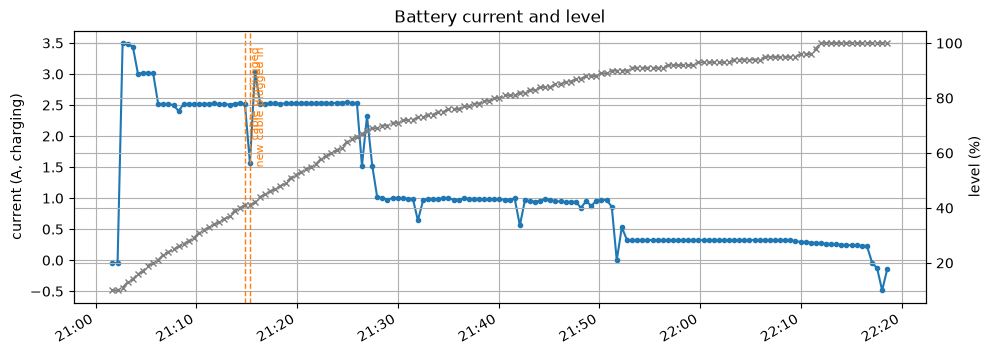

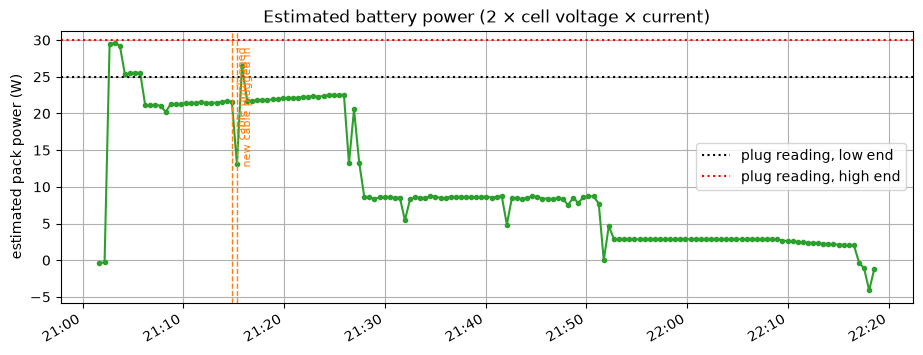

In [26]:
fig, ax1 = plt.subplots()
ax1.plot(bat.time, -bat.current_ma / 1000, 'o-', ms=3, label='battery current (A)')
ax1.set_ylabel('current (A, charging)')
ax2 = ax1.twinx()
ax2.plot(bat.time, bat.level, 'x--', color='tab:gray', ms=4, label='level (%)')
ax2.set_ylabel('level (%)')
ax1.set_title('Battery current and level')
mark_cables(ax1)
hhmm(fig)
plt.show()

fig, ax = plt.subplots()
ax.plot(bat.time, bat.power_w, 'o-', ms=3, color='tab:green')
ax.set_ylabel('estimated pack power (W)')
ax.set_title('Estimated battery power (2 × cell voltage × current)')
ax.axhline(25, ls=':', color='k', label='plug reading, low end')
ax.axhline(30, ls=':', color='r', label='plug reading, high end')
ax.legend()
mark_cables(ax)
hhmm(fig)
plt.show()

## 2. Charge phases

A phase change is a change in the per-cell `max_current` ceiling. The table below pairs each phase with the battery readings taken closest in time.

In [27]:
cell0 = bcc[bcc.cell == 0].sort_values('time').copy()
cell0['phase'] = (cell0.max_current_ma != cell0.max_current_ma.shift()).cumsum()
phases = cell0.groupby('phase').agg(
    start=('time', 'min'), end=('time', 'max'),
    ceiling_ma=('max_current_ma', 'max'),
    mean_charge_ma=('charge_current_ma', 'mean'),
    mean_temp_dc=('temp_dc', 'mean'),
    records=('time', 'size'),
).reset_index(drop=True)

bat_s = bat.sort_values('time')
phases['level_start'] = pd.merge_asof(phases[['start']].sort_values('start'), bat_s[['time', 'level']],
                                      left_on='start', right_on='time', direction='nearest')['level'].values
phases['level_end'] = pd.merge_asof(phases[['end']].sort_values('end'), bat_s[['time', 'level']],
                                    left_on='end', right_on='time', direction='nearest')['level'].values
phases['pack_power_w'] = pd.merge_asof(phases[['end']].sort_values('end'), bat_s[['time', 'power_w']],
                                       left_on='end', right_on='time', direction='nearest')['power_w'].values
phases[['start', 'end', 'ceiling_ma', 'mean_charge_ma', 'mean_temp_dc', 'level_start', 'level_end', 'pack_power_w']].round(1)

,start,end,ceiling_ma,mean_charge_ma,mean_temp_dc,level_start,level_end,pack_power_w
0,2026-10-26 21:02:31.055,2026-10-26 21:02:33.125,7300,7089.0,232.0,11,11,29.5
1,2026-10-26 21:02:34.160,2026-10-26 21:02:42.420,4200,3989.2,239.3,11,11,29.5
2,2026-10-26 21:03:52.666,2026-10-26 21:03:55.776,3500,3500.0,260.0,14,14,29.2
3,2026-10-26 21:03:56.812,2026-10-26 21:06:15.735,3000,3000.0,251.7,14,21,21.1
4,2026-10-26 21:06:16.770,2026-10-26 21:14:52.202,2500,2500.0,232.1,21,41,21.6
5,2026-10-26 21:15:22.090,2026-10-26 21:15:25.177,7300,6505.8,221.0,41,41,13.1
6,2026-10-26 21:15:26.208,2026-10-26 21:15:48.971,4200,3409.7,225.7,41,42,26.4
7,2026-10-26 21:15:50.014,2026-10-26 21:15:56.240,4000,2500.0,232.1,42,42,26.4
8,2026-10-26 21:15:57.289,2026-10-26 21:16:03.563,3500,2500.0,234.1,42,42,26.4
9,2026-10-26 21:16:04.603,2026-10-26 21:16:10.839,3000,2500.0,235.6,44,44,21.8


## 3. Per-cell limits and requests

`max_current` is the HAL's ceiling, `charge_current` is the value it chose, and the requests are what it sent to the charger.

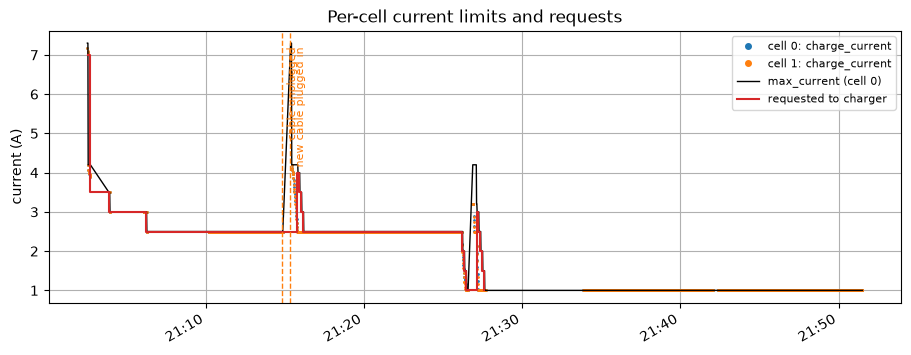

In [28]:
fig, ax = plt.subplots()
for c, g in bcc.groupby('cell'):
    ax.plot(g.time, g.charge_current_ma / 1000, '.', ms=2, label=f'cell {c}: charge_current')
ax.plot(cell0.time, cell0.max_current_ma / 1000, '-', color='k', lw=1, label='max_current (cell 0)')
if len(req):
    ax.step(req.time, req.requested_ma / 1000, where='post', color='tab:red', label='requested to charger')
ax.set_ylabel('current (A)')
ax.set_title('Per-cell current limits and requests')
ax.legend(markerscale=4, fontsize=8)
mark_cables(ax)
hhmm(fig)
plt.show()

## 4. Temperature

Temperature is in tenths of °C in both logs. The SVOOC thermal table gives no cap below 37 °C, so any drop in current here comes from the charge logic, not from heat.

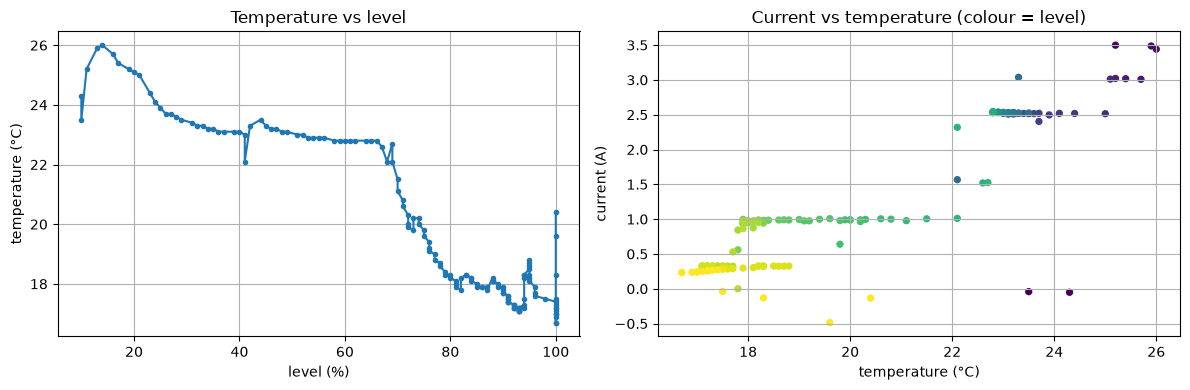

In [29]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(bat.level, bat.temp_dc / 10, 'o-', ms=3)
a1.set_xlabel('level (%)'); a1.set_ylabel('temperature (°C)'); a1.set_title('Temperature vs level')
a2.scatter(bat.temp_dc / 10, -bat.current_ma / 1000, c=bat.level, cmap='viridis', s=18)
a2.set_xlabel('temperature (°C)'); a2.set_ylabel('current (A)'); a2.set_title('Current vs temperature (colour = level)')
plt.tight_layout()
plt.show()

## 5. Cell balance

Series cells should carry the same current. A growing voltage gap between cells points to imbalance.

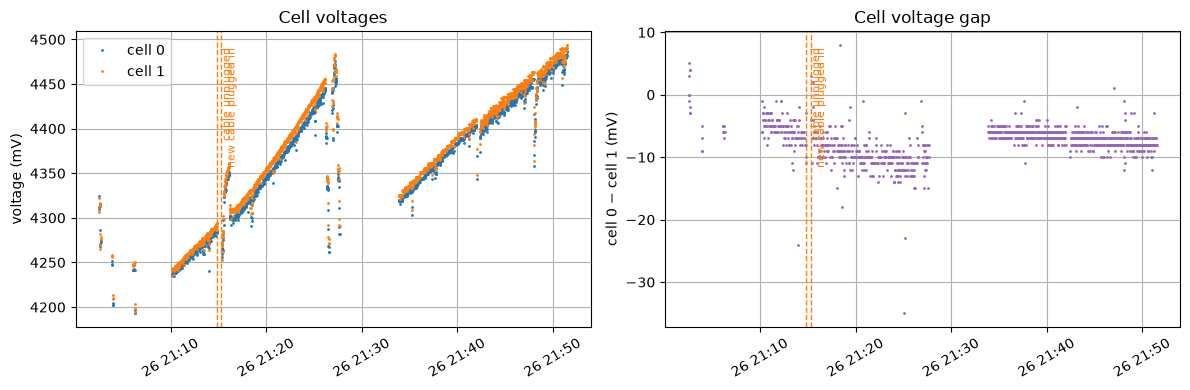

max absolute gap (mV): 35.0


In [30]:
piv = bcc.pivot_table(index='time', columns='cell', values='voltage_mv', aggfunc='mean')
piv['gap_mv'] = piv[0] - piv[1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(piv.index, piv[0], '.', ms=2, label='cell 0')
a1.plot(piv.index, piv[1], '.', ms=2, label='cell 1')
a1.set_ylabel('voltage (mV)'); a1.set_title('Cell voltages'); a1.legend()
a2.plot(piv.index, piv['gap_mv'], '.', ms=2, color='tab:purple')
a2.set_ylabel('cell 0 − cell 1 (mV)'); a2.set_title('Cell voltage gap')
mark_cables(a1); mark_cables(a2)
for a in (a1, a2):
    a.tick_params(axis='x', labelrotation=30)
plt.tight_layout()
plt.show()
print('max absolute gap (mV):', piv['gap_mv'].abs().max().round(0))

## 6. Anode potential

The HAL logs `anode_potential` per cell. The HAL reduces current when this drops below zero. Its units are not confirmed, so the axis is shown as logged.

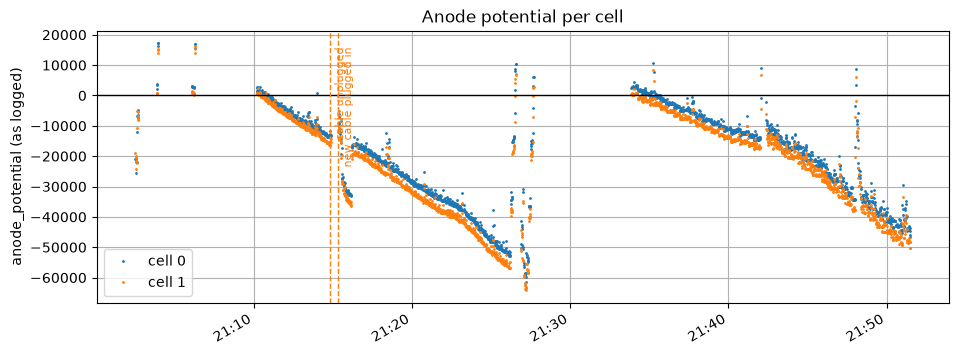

In [31]:
fig, ax = plt.subplots()
for c, g in bcc.groupby('cell'):
    ax.plot(g.time, g.anode_potential, '.', ms=2, label=f'cell {c}')
ax.axhline(0, color='k', lw=1)
ax.set_ylabel('anode_potential (as logged)')
ax.set_title('Anode potential per cell')
ax.legend()
mark_cables(ax)
hhmm(fig)
plt.show()

## 7. Wall meter (smart plug)

The plug's power sensor is exported from Home Assistant in UTC. It is converted to Berlin time (UTC+1 on this date) so it lines up with the phone logs. It updates only every few minutes, so it is drawn as a step line. The battery power is the estimate from section 1.

plug readings: 14 2026-10-26 20:30:00 -> 2026-10-26 22:12:00.161000


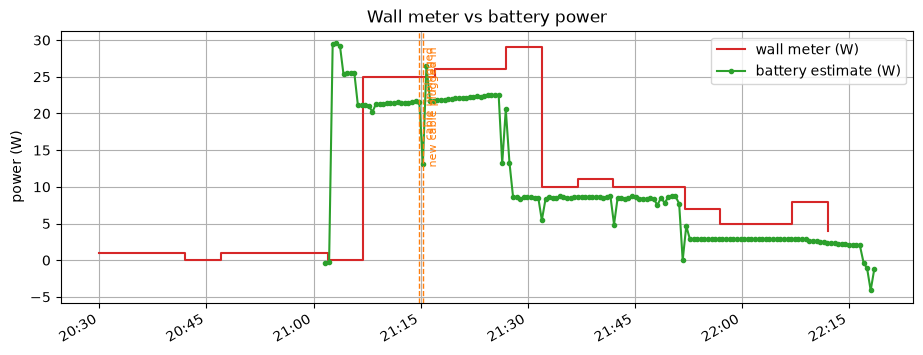

matched samples: 113
median battery/wall ratio: 0.78


In [32]:
plug = pd.read_csv('../logs/power_plug_history.csv')
plug = plug[plug.entity_id == 'sensor.network_energy_power_2'].copy()
plug['watts'] = pd.to_numeric(plug.state, errors='coerce')
plug = plug.dropna(subset=['watts'])
plug['time'] = (pd.to_datetime(plug.last_changed, utc=True)
                  .dt.tz_convert('Europe/Berlin').dt.tz_localize(None))
plug = plug.sort_values('time')[['time', 'watts']]
print('plug readings:', len(plug), plug.time.min(), '->', plug.time.max())

fig, ax = plt.subplots()
ax.step(plug.time, plug.watts, where='post', color='tab:red', label='wall meter (W)')
ax.plot(bat.time, bat.power_w, 'o-', ms=3, color='tab:green', label='battery estimate (W)')
mark_cables(ax)
ax.set_ylabel('power (W)')
ax.set_title('Wall meter vs battery power')
ax.legend()
hhmm(fig)
plt.show()

both = pd.merge_asof(bat[['time', 'power_w']].sort_values('time'), plug,
                     on='time', direction='nearest', tolerance=pd.Timedelta('3min')).dropna()
both['ratio_battery_over_wall'] = both.power_w / both.watts
print('matched samples:', len(both))
print('median battery/wall ratio:', round(both.ratio_battery_over_wall.median(), 2))

## Caveats

- The `bcc_log` SOC field is an internal value and does not match the UI level. Use `level` from `dumpsys` for the x-axis.
- Pack voltage is estimated as 2 × cell voltage. Confirm with the wall meter at the same time.
- `anode_potential` units are not confirmed. The HAL's 0 V cut-off is inferred from the code, not measured.
- Phases come from the per-cell `max_current` steps. A short logcat buffer or gaps in logging can hide a step.